In [8]:
import os
from pathlib import Path
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import RMSprop
import matplotlib.pyplot as plt

ROOT_DIR = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent

class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if logs.get('accuracy') is not None and logs.get('accuracy') >= 0.999:
            print('\nДосягнуто 99,9% точності, тому скасовуємо навчання!')
            self.model.stop_training = True

callbacks = myCallback()

model = tf.keras.models.Sequential([

    tf.keras.layers.Input(shape=(150, 150, 3)),
    tf.keras.layers.Conv2D(16, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')

])

model.compile(
    loss='binary_crossentropy',
    optimizer=RMSprop(learning_rate=0.001),
    metrics=['accuracy']
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 148, 148, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 74, 74, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 72, 72, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 34, 34, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 18496)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │     9,470,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,494,561 (36.22 MB)

 Trainable params: 9,494,561 (36.22 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
train_datagen = ImageDataGenerator(rescale=1/255.0)

train_generator = train_datagen.flow_from_directory(
    str(ROOT_DIR / 'data' / 'HappyVsSad' / 'data'),
    target_size=(150, 150),
    batch_size=10,
    class_mode='binary'
)

history = model.fit(
    train_generator,
    epochs=15,
    verbose=1,
    callbacks=[callbacks]
)

Found 80 images belonging to 2 classes.
Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.6000 - loss: 2.0340
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.6375 - loss: 0.6293
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.8750 - loss: 0.3649
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.8625 - loss: 0.3048
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step - accuracy: 0.9625 - loss: 0.1682
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.9250 - loss: 0.1538
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.9500 - loss: 0.1535
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.9750 - loss: 0.0754
Epoch 9/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.9250 - loss: 0.1495
Epoch 10/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 1.0000 - loss: 0.0388
Досягнуто 99,9% точності, тому скасовуємо навчання!
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 1.0000 - loss: 0.0388


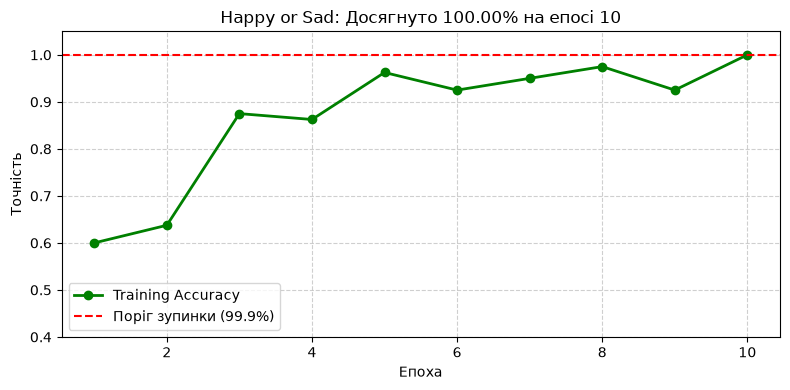

In [10]:
acc = history.history['accuracy']
epochs = range(1, len(acc) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, acc, 'go-', linewidth=2, label='Training Accuracy')
plt.axhline(0.999, color='red', linestyle='--', label='Поріг зупинки (99.9%)')
plt.title(f'Happy or Sad: Досягнуто {acc[-1]*100:.2f}% на епосі {len(acc)}')
plt.xlabel('Епоха')
plt.ylabel('Точність')
plt.ylim(0.4, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

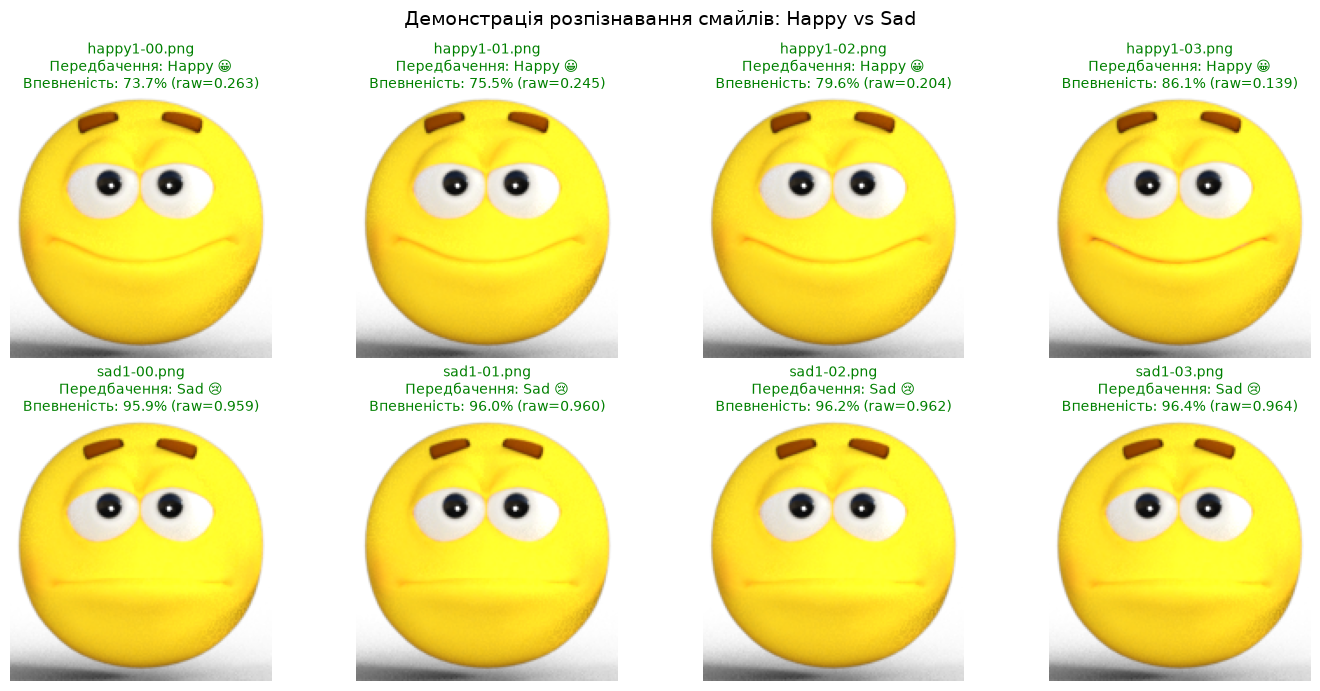

In [11]:
import numpy as np
from tensorflow.keras.preprocessing import image
from PIL import Image

happy_dir = ROOT_DIR / 'data' / 'HappyVsSad' / 'data' / 'happy'
sad_dir = ROOT_DIR / 'data' / 'HappyVsSad' / 'data' / 'sad'

happy_files = sorted(list(happy_dir.glob('*.png')) + list(happy_dir.glob('*.jpg')))[:4]
sad_files = sorted(list(sad_dir.glob('*.png')) + list(sad_dir.glob('*.jpg')))[:4]
sample_files = happy_files + sad_files

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for idx, img_path in enumerate(sample_files):
    img = image.load_img(img_path, target_size=(150, 150))
    x = np.expand_dims(image.img_to_array(img) / 255.0, axis=0)
    prob = float(model.predict(x, verbose=0)[0][0])
    
    pred_label = 'Sad 😢' if prob > 0.5 else 'Happy 😀'
    true_label = 'Happy' if 'happy' in str(img_path) else 'Sad'
    conf = prob if prob > 0.5 else (1.0 - prob)
    is_correct = pred_label.startswith(true_label)
    
    display_img = Image.open(img_path)
    axes[idx].imshow(display_img)
    color = 'green' if is_correct else 'red'
    axes[idx].set_title(f'{img_path.name}\nПередбачення: {pred_label}\nВпевненість: {conf*100:.1f}% (raw={prob:.3f})',
                        color=color, fontsize=10)
    axes[idx].axis('off')

plt.suptitle('Демонстрація розпізнавання смайлів: Happy vs Sad', fontsize=14)
plt.tight_layout()
plt.show()